# Reward alignment and reward-magnitude tuning — normalized dF/F, sessions 216–231

Compare the **same cells and reward trials** with standard maximin dF/F, paired-red OLS dF/F, the earlier whole-recording 20th-percentile dF/F (recomputed), and the existing `plane0/dff.npy` loaded directly. The latter two remain separate even when their values match. Choose a session/run below. The reviewed acquisition mapping supplies H5 and behavior files; run numbers are not assumed to match.

`SOURCE_MODE='recompute'` calculates standard and paired-red OLS exactly as in the new comparison notebook (default settings), so no large trace export is needed first. Set `SOURCE_MODE='saved'` to use the actual exported methods/settings from `compare_F_F0_dff_216_231.ipynb` (enable its `SAVE_RESULTS` and run its save cell). Existing fluorescence inputs are never overwritten.

All methods use a common artifact/clock/finite-data mask and common trial eligibility. No interpolation bridges excluded or removed frames. Per-trial baseline subtraction is enabled, as in the original reward notebook: this removes the pre-reward offset **after** dF/F normalization. Magnitude preferences and rankings are descriptive, not significance tests. Cells selected and evaluated on the same trials can appear more responsive by selection alone.

Default: **session 216/run-04**. Run-01 aligns successfully but is a port-finding recording without canonical bandit trial records; it is not suitable for this reward-tuning parser.

In [4]:
from pathlib import Path
import csv, json, pickle, subprocess, sys, importlib.util
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, minimum_filter1d, maximum_filter1d
from sklearn.linear_model import LinearRegression
from IPython.display import display, Image

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'scripts/convert_seg_to_stat_216_231.py').exists())
sys.path.insert(0, str(ROOT / 'scripts'))
from reward_dff_comparison import frame_indices, peri_event, mean_sem
from calculate_run_dff import calculate_dff
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.dpi': 110, 'legend.frameon': False})


## Choose one recording and methods

In [5]:
SESSION, RUN = 216, 4
SOURCE_MODE = 'recompute'  # 'recompute' or 'saved'
METHODS = ['standard_green', 'paired_red_ols_unscaled']
INCLUDE_PERCENTILE_REFERENCE = True
INCLUDE_SAVED_DFF = True  # Fourth method: read plane0/dff.npy, never regenerate it.
RANKING_METHOD = 'standard_green'  # Same ROI ordering for every method.
ONLY_ISCELL = True
ROI_IDS = None  # None: rank the top 12 cells; or explicit ORIGINAL ROI IDs.
N_ROIS_TO_PLOT = 12
WINDOW_S = (-5., 10.)
BASELINE_S = (-2., -.5)
RESPONSE_S = (0., 2.)
TUNING_BASELINE_S = (-1., 0.)
TUNING_RESPONSE_S = (0., 1.)
BASELINE_CORRECT = True
MIN_VALID_FRACTION = .8  # Per-trial baseline and response coverage; common to methods.
SAVE_FIGURES = False
SAVE_ARRAYS = False

SUBJECT = Path('/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R')
BEHAVIOR_PROJECT = Path('/Users/megyoung/magnitude-bandit-analysis')
MATCH_CSV = ROOT / 'output/frame_behavior/behavior_matches_sessions216-231_reviewed.csv'
DFF_DIR = ROOT / 'output/compare_F_F0_dff_216_231' / f'ses-{SESSION}_run-{RUN:02d}'
OUTPUT_DIR = ROOT / 'output/reward_dff_comparison_216_231' / f'ses-{SESSION}_run-{RUN:02d}'
if SESSION not in range(216,232) or SOURCE_MODE not in ('saved', 'recompute'):
    raise ValueError('Choose session 216–231 and a valid SOURCE_MODE')
planes = sorted(SUBJECT.glob(f'ses-{SESSION}_*/funcimg/run-{RUN:02d}/suite2p/plane0'))
if len(planes) != 1: raise ValueError(f'Expected exactly one input plane: {planes}')
PLANE_DIR = planes[0]
with MATCH_CSV.open() as f:
    matches = [r for r in csv.DictReader(f) if int(r['session']) == SESSION and int(r['run']) == RUN]
if len(matches) != 1 or matches[0]['status'] != 'CONFIRMED':
    raise ValueError('No unique CONFIRMED acquisition/behavior match. Review mapping first.')
match = matches[0]
run_dir = PLANE_DIR.parents[1]
source_manifest = run_dir / 'source_tiff.json'
if source_manifest.exists():
    source_tiff = Path(json.loads(source_manifest.read_text())['source_tiff'])
else:
    sources = {Path(json.loads(p.read_text())['input_tiff'])
               for p in run_dir.glob('*.phase.json') if not p.name.startswith('.')}
    if len(sources) != 1: raise ValueError('Ambiguous source TIFF provenance')
    source_tiff = sources.pop()
if source_tiff.name != match['imaging_tiff']:
    raise ValueError('Reviewed mapping disagrees with preprocessing TIFF provenance')
H5_PATH = source_tiff.parent / match['h5']
BEHAVIOR_TSV = Path(match['behavior_path'])
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Plane:', PLANE_DIR)
print('H5:', H5_PATH)
print('Behavior:', BEHAVIOR_TSV)


Plane: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-216_date-20260730/funcimg/run-04/suite2p/plane0
H5: /Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01/sub-03_id-MY_71_R/ses-216_date-20260730/funcimg/file_01623.h5
Behavior: /Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01/sub-03_id-MY_71_R/ses-216_date-20260730/behav/MY_71_R-2026-07-30-131527.tsv


## Load or recompute normalized methods

Recomputed defaults match the new comparison notebook: derivative-z threshold 3, fraction of cells 0.25, one-frame padding, internal interpolation before regression, and NaNs at artifacts afterward. Neuropil subtraction and baseline settings come from each run's ops. No display rescaling is used in this analysis.

`saved_dff_npy` reads the selected run's actual `dff.npy`, preserves its values and uses the same original-frame selection. Its available metadata and numerical agreement with the recomputed percentile reference are printed before analysis. All four methods then receive the same common sample exclusions and optional pre-reward offset subtraction; neither step rewrites the source file. Coincident curves are expected when saved and recomputed values match.


In [6]:
ops = np.load(PLANE_DIR / 'ops.npy', allow_pickle=True).item()
defaults = dict(neucoeff=.7, baseline='maximin', win_baseline=60., sig_baseline=10.,
                prctile_baseline=8., fs=7.52)
for key, value in defaults.items(): ops.setdefault(key, value)
raw = np.load(PLANE_DIR / 'F.npy', mmap_mode='r')
neu = np.load(PLANE_DIR / 'Fneu.npy', mmap_mode='r')
if raw.ndim != 2 or raw.shape != neu.shape: raise ValueError('F/Fneu shapes differ')
n_rois, n_original = raw.shape
if n_original != int(match['n_frames']): raise ValueError('Frame count differs from reviewed acquisition')
iscell = np.load(PLANE_DIR / 'iscell.npy')[:,0].astype(bool)
if len(iscell) != n_rois: raise ValueError('iscell/F ROI counts differ')
Fc = raw.astype(np.float32) - ops['neucoeff'] * neu.astype(np.float32)

def normalized(values):
    baseline = ops['baseline']
    if baseline == 'maximin':
        f0 = gaussian_filter(values, sigma=(0,float(ops['sig_baseline'])))
        window = max(1,int(ops['win_baseline']*ops['fs']))
        f0 = maximum_filter1d(minimum_filter1d(f0,window,axis=1),window,axis=1)
    elif baseline == 'constant':
        smooth = gaussian_filter(values,sigma=(0,float(ops['sig_baseline'])))
        f0 = np.broadcast_to(smooth.min(axis=1,keepdims=True),values.shape)
    elif baseline in ('constant_prctile','prctile'):
        f0 = np.broadcast_to(np.percentile(values,ops['prctile_baseline'],axis=1,keepdims=True),values.shape)
    else:
        raise ValueError(f'Unsupported baseline: {baseline}')
    return ((values-f0)/np.maximum(f0.mean(axis=1,keepdims=True),1e-3)).astype(np.float32)

def interpolate_artifacts(values, mask):
    clean = values.astype(np.float32).copy()
    frames = np.arange(clean.shape[1])
    for roi in range(len(clean)):
        keep = ~mask & np.isfinite(clean[roi])
        clean[roi,mask] = np.interp(frames[mask],frames[keep],clean[roi,keep]) if keep.sum() >= 2 else np.nan
    return clean

if SOURCE_MODE == 'saved':
    manifest = json.loads((DFF_DIR / 'dff_methods.json').read_text())
    if Path(manifest['source_plane_dir']).resolve() != PLANE_DIR.resolve():
        raise ValueError('Saved methods refer to a different plane')
    if 'normalization' not in manifest:
        raise ValueError('Re-export with the NEW normalized comparison notebook')
    if manifest['n_rois'] != n_rois: raise ValueError('Saved ROI count differs from current F')
    selector = None
    if manifest.get('valid_frames_path'):
        with np.load(manifest['valid_frames_path']) as data: selector = data['valid_frames']
    original_ids = frame_indices(selector, n_original)
    methods = {name: np.load(DFF_DIR / manifest['methods'][name]['dff_file'])
               for name in METHODS}
    artifacts = np.load(DFF_DIR / manifest['artifact_detection']['mask_file']).astype(bool)
    normalization_source = manifest['normalization']
else:
    if not set(METHODS) <= {'standard_green','paired_red_ols_unscaled'}:
        raise ValueError('Other methods require SOURCE_MODE=saved and exported arrays')
    original_ids = np.arange(n_original)
    initial = normalized(Fc)
    derivative = np.diff(initial.astype(float),axis=1,prepend=initial[:,:1])
    center = np.nanmedian(derivative,axis=1,keepdims=True)
    scale = 1.4826*np.nanmedian(np.abs(derivative-center),axis=1,keepdims=True)
    scale[scale < 1e-12] = np.nan
    candidates = np.any(np.isfinite(initial),axis=1)
    if np.any(iscell): candidates &= iscell
    if not candidates.any(): raise ValueError('No finite cells for artifact detection')
    fraction = np.mean((np.abs((derivative-center)/scale) >= 3.)[candidates],axis=0)
    artifacts = np.convolve((fraction >= .25).astype(int),np.ones(3),mode='same') > 0
    green = interpolate_artifacts(Fc, artifacts)
    methods = {'standard_green': normalized(green)}
    if 'paired_red_ols_unscaled' in METHODS:
        red = np.load(PLANE_DIR / 'F_chan2.npy').astype(np.float32)
        red_neu = np.load(PLANE_DIR / 'Fneu_chan2.npy').astype(np.float32)
        if red.shape != Fc.shape or red_neu.shape != Fc.shape: raise ValueError('Channel shapes differ')
        red = interpolate_artifacts(red - ops['neucoeff']*red_neu, artifacts)
        predictor = red - np.nanmedian(red,axis=1,keepdims=True)
        corrected = green.astype(float).copy()
        for roi,y in enumerate(green):
            keep = ~artifacts & np.isfinite(y) & np.isfinite(predictor[roi])
            if keep.sum() >= 5:
                model = LinearRegression().fit(predictor[roi,keep,None],y[keep])
                corrected[roi] = y - model.coef_[0]*predictor[roi]
        methods['paired_red_ols_unscaled'] = normalized(corrected)
    methods = {name: methods[name] for name in METHODS}
    for value in methods.values(): value[:,artifacts] = np.nan
    normalization_source = '(Fc-F0)/max(mean(F0),1e-3); comparison notebook defaults'

if INCLUDE_PERCENTILE_REFERENCE:
    # Recompute the old formula from the same raw data to avoid stale cached arrays.
    methods['percentile20_reference'] = calculate_dff(raw,neu,ops['neucoeff'])['dff'][:,original_ids].astype(np.float32)
saved_dff_metadata = None
saved_dff_check = None
SAVED_DFF_PATH = PLANE_DIR / 'dff.npy'
if INCLUDE_SAVED_DFF:
    saved_dff = np.load(SAVED_DFF_PATH, mmap_mode='r')
    if saved_dff.shape != (n_rois, n_original):
        raise ValueError(f'Saved dff.npy shape {saved_dff.shape} differs from original F '
                         f'{(n_rois, n_original)}; do not guess ROI/frame correspondence.')
    # Preserve saved values: no neuropil correction or normalization is reapplied.
    methods['saved_dff_npy'] = np.asarray(saved_dff[:, original_ids])
    metadata_path = PLANE_DIR / 'dff_metadata.json'
    if metadata_path.exists():
        saved_dff_metadata = json.loads(metadata_path.read_text())
    print('Directly loaded:', SAVED_DFF_PATH)
    print('Saved dF/F metadata:', saved_dff_metadata if saved_dff_metadata else 'not available')
    if 'percentile20_reference' in methods:
        previous = methods['percentile20_reference']
        saved = methods['saved_dff_npy']
        finite = np.isfinite(previous) & np.isfinite(saved)
        saved_dff_check = dict(
            matches_recomputed_percentile20=bool(np.allclose(saved, previous, rtol=1e-5, atol=1e-6, equal_nan=True)),
            same_finite_mask=bool(np.array_equal(np.isfinite(saved), np.isfinite(previous))),
            max_absolute_difference=float(np.max(np.abs(saved[finite]-previous[finite]))) if finite.any() else None)
        print('Saved versus recomputed 20th-percentile (before common exclusions):', saved_dff_check)

expected = (n_rois,len(original_ids))
if artifacts.shape != (len(original_ids),) or any(a.shape != expected for a in methods.values()):
    raise ValueError('Method/mask/frame-selector shapes differ')
if RANKING_METHOD not in methods: raise ValueError('Ranking method not loaded')
print('Methods:', list(methods), '| shape:', expected)
print('Excluded upstream artifact frames:', int(artifacts.sum()))


Directly loaded: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-216_date-20260730/funcimg/run-04/suite2p/plane0/dff.npy
Saved dF/F metadata: {'plane': '/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-216_date-20260730/funcimg/run-04/suite2p/plane0', 'baseline': 'whole-recording percentile', 'percentile': 20, 'min_f0': 0, 'neucoeff': 0.7, 'fs': 7.52, 'functional_chan': 2}
Saved versus recomputed 20th-percentile (before common exclusions): {'matches_recomputed_percentile20': True, 'same_finite_mask': True, 'max_absolute_difference': 4.409257513771081e-06}
Methods: ['standard_green', 'paired_red_ols_unscaled', 'percentile20_reference', 'saved_dff_npy'] | shape: (400, 8503)
Excluded upstream artifact frames: 0


## Align the clocks once for all methods

Uses the same rsync alignment and canonical behavioral trial parser as the existing reward notebook. The reviewed mapping must be CONFIRMED. H5 frames without rsync coverage remain invalid. A single extra final trace frame is retained with an unknown timestamp.

ScanImage frames: 8503
Rsync pulses: pyControl=222, ScanImage=222, matched=222
Aligned frames within rsync coverage: 8349/8503
Saved: /Users/megyoung/mini2p-preprocessing/output/reward_dff_comparison_216_231/ses-216_run-04/aligned_session.pkl

Matched pulses: 222
Median / maximum chunk RMS (ms): 0.08944271912838192 0.3346640106111517
Covered frames: 8349 / 8503


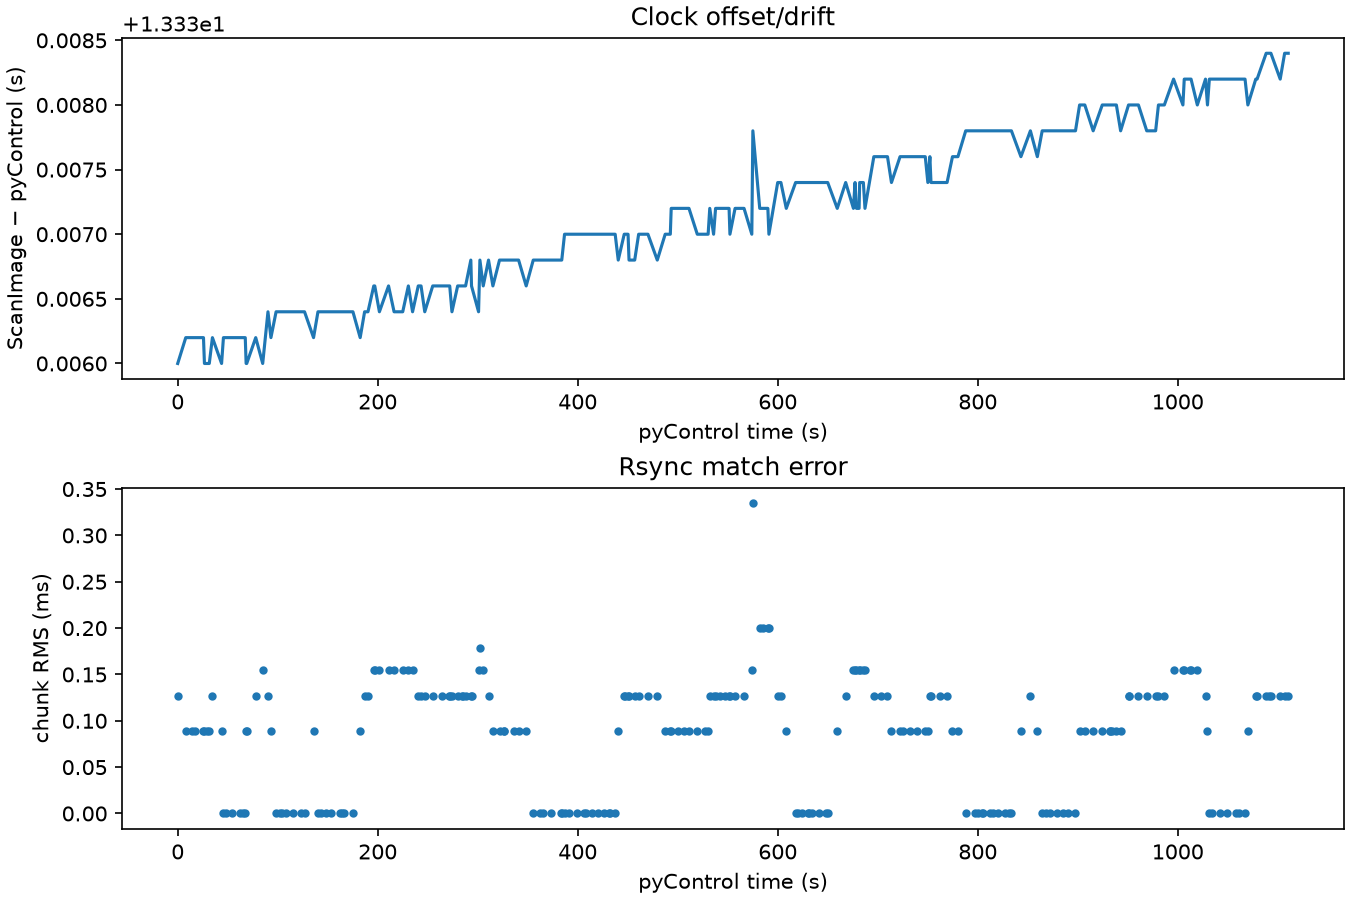

In [7]:
ALIGN_PYTHON = Path(sys.executable)
if importlib.util.find_spec('h5py') is None:
    ALIGN_PYTHON = Path('/Users/megyoung/anaconda3/bin/python')
ALIGNED_SESSION = OUTPUT_DIR / 'aligned_session.pkl'
QC_PLOT = OUTPUT_DIR / 'rsync_qc.png'
command = [str(ALIGN_PYTHON),str(ROOT/'scripts/align_scanimage_pycontrol.py'),
           '--h5',str(H5_PATH),'--behavior-tsv',str(BEHAVIOR_TSV),
           '--behavior-project',str(BEHAVIOR_PROJECT),'--output',str(ALIGNED_SESSION),
           '--plot',str(QC_PLOT)]
result = subprocess.run(command,text=True,capture_output=True)
print(result.stdout)
if result.returncode:
    raise RuntimeError(result.stderr)
with ALIGNED_SESSION.open('rb') as f: session = pickle.load(f)
rsync = session['rsync']
if len(rsync['matched_pycontrol_indices']) < 10 or np.max(np.abs(rsync['residual_ms'])) > 50:
    raise ValueError('Rsync QC failed; inspect acquisition match')
all_times = np.asarray(session['frame_times_pycontrol_s'],float)
all_valid = np.asarray(session['frame_valid'],bool)
if len(all_times) == n_original-1:
    all_times = np.r_[all_times,np.nan]
    all_valid = np.r_[all_valid,False]
elif len(all_times) != n_original:
    raise ValueError('H5/fluorescence frame count mismatch')
frame_times = all_times[original_ids]
clock_valid = all_valid[original_ids] & np.isfinite(frame_times)
bad = np.asarray(ops.get('badframes',np.zeros(n_original,bool)))
if bad.dtype != bool or bad.shape != (n_original,):
    raise ValueError('Expected one Boolean ops badframes flag per original frame')
common_valid = clock_valid[None,:] & (~artifacts)[None,:] & (~bad[original_ids])[None,:]
common_valid = common_valid & np.logical_and.reduce([np.isfinite(a) for a in methods.values()])
print('Matched pulses:',len(rsync['matched_pycontrol_indices']))
print('Median / maximum chunk RMS (ms):',np.median(rsync['chunk_rms_s'])*1000,np.max(rsync['chunk_rms_s'])*1000)
print('Covered frames:',int(clock_valid.sum()),'/',len(clock_valid))
display(Image(filename=str(QC_PLOT)))


## Reward onsets and common trial coverage

As in the original notebook, rewarded trials use entry into the `choice` state immediately before reward delivery. The number of these entries must equal the number of rewarded trials. The full pre/post window must fall within the clock's range; gaps within it remain NaN. Baseline and response windows require at least 80% valid samples per ROI/trial. Trial eligibility is identical across methods.

In [8]:
if 'reward_pulses' not in session or 'choice' not in session['events']:
    raise ValueError('This recording has no canonical rewarded bandit trials/choice events. Choose a task run such as session 216/run-04; port-finding runs require a separate event definition.')
reward_pulses = np.asarray(session['reward_pulses'],float)
trial_ids = np.flatnonzero(reward_pulses > 0)
onsets = np.asarray(session['events']['choice']['time_s'],float)
if len(onsets) != len(trial_ids) or np.any(np.diff(onsets) <= 0):
    raise ValueError('Reward trial/event counts or ordering disagree; inspect task version')
clock = frame_times[clock_valid]
dt = float(np.nanmedian(np.diff(np.asarray(session['frame_times_scanimage_s'],float))))
relative_time = np.arange(WINDOW_S[0],WINDOW_S[1]+dt/2,dt)
covered = np.isfinite(onsets) & (onsets+WINDOW_S[0] >= clock.min()) & (onsets+WINDOW_S[1] <= clock.max())
reward_onsets = onsets[covered]
reward_trial_ids = trial_ids[covered]
reward_magnitudes = reward_pulses[reward_trial_ids]
if len(reward_onsets) == 0: raise ValueError('No fully covered reward windows')
baseline_mask = (relative_time >= BASELINE_S[0]) & (relative_time < BASELINE_S[1])
response_mask = (relative_time >= RESPONSE_S[0]) & (relative_time <= RESPONSE_S[1])
if not baseline_mask.any() or not response_mask.any(): raise ValueError('Empty analysis window')
eligible_rois = np.any(common_valid,axis=1) & (iscell if ONLY_ISCELL else True)
peri = {}
for name,values in methods.items():
    a = peri_event(values,frame_times,original_ids,common_valid,reward_onsets,relative_time,1.5*dt)
    baseline_ok = np.mean(np.isfinite(a[:,:,baseline_mask]),axis=2) >= MIN_VALID_FRACTION
    response_ok = np.mean(np.isfinite(a[:,:,response_mask]),axis=2) >= MIN_VALID_FRACTION
    eligible_trials = baseline_ok & response_ok & eligible_rois[None,:]
    if BASELINE_CORRECT:
        a -= mean_sem(a[:,:,baseline_mask],axis=2)[0][:,:,None]
    a[~eligible_trials] = np.nan
    peri[name] = a
# Assert the sampling and trial exclusions really are shared.
reference_valid = np.isfinite(peri[RANKING_METHOD])
assert all(np.array_equal(reference_valid,np.isfinite(a)) for a in peri.values())
magnitudes = np.unique(reward_magnitudes)
print('Rewards with full clock-range coverage:',len(reward_onsets))
print('Reward pulse counts:',dict(zip(*np.unique(reward_magnitudes,return_counts=True))))
print('ROIs eligible for analysis:',int(eligible_rois.sum()))
print('Baseline subtraction:',BASELINE_CORRECT,'| windows:',BASELINE_S,RESPONSE_S)


Rewards with full clock-range coverage: 17
Reward pulse counts: {np.float64(1.0): np.int64(5), np.float64(2.0): np.int64(1), np.float64(3.0): np.int64(8), np.float64(4.0): np.int64(3)}
ROIs eligible for analysis: 369
Baseline subtraction: True | windows: (-2.0, -0.5) (0.0, 2.0)


## Same-cell comparison of mean reward responses

Rank once by absolute 0–2 s response in the chosen ranking method; use those ROI IDs for every method. Curves show trial mean ± SEM in actual normalized dF/F units, with no stacked-trace rescaling.

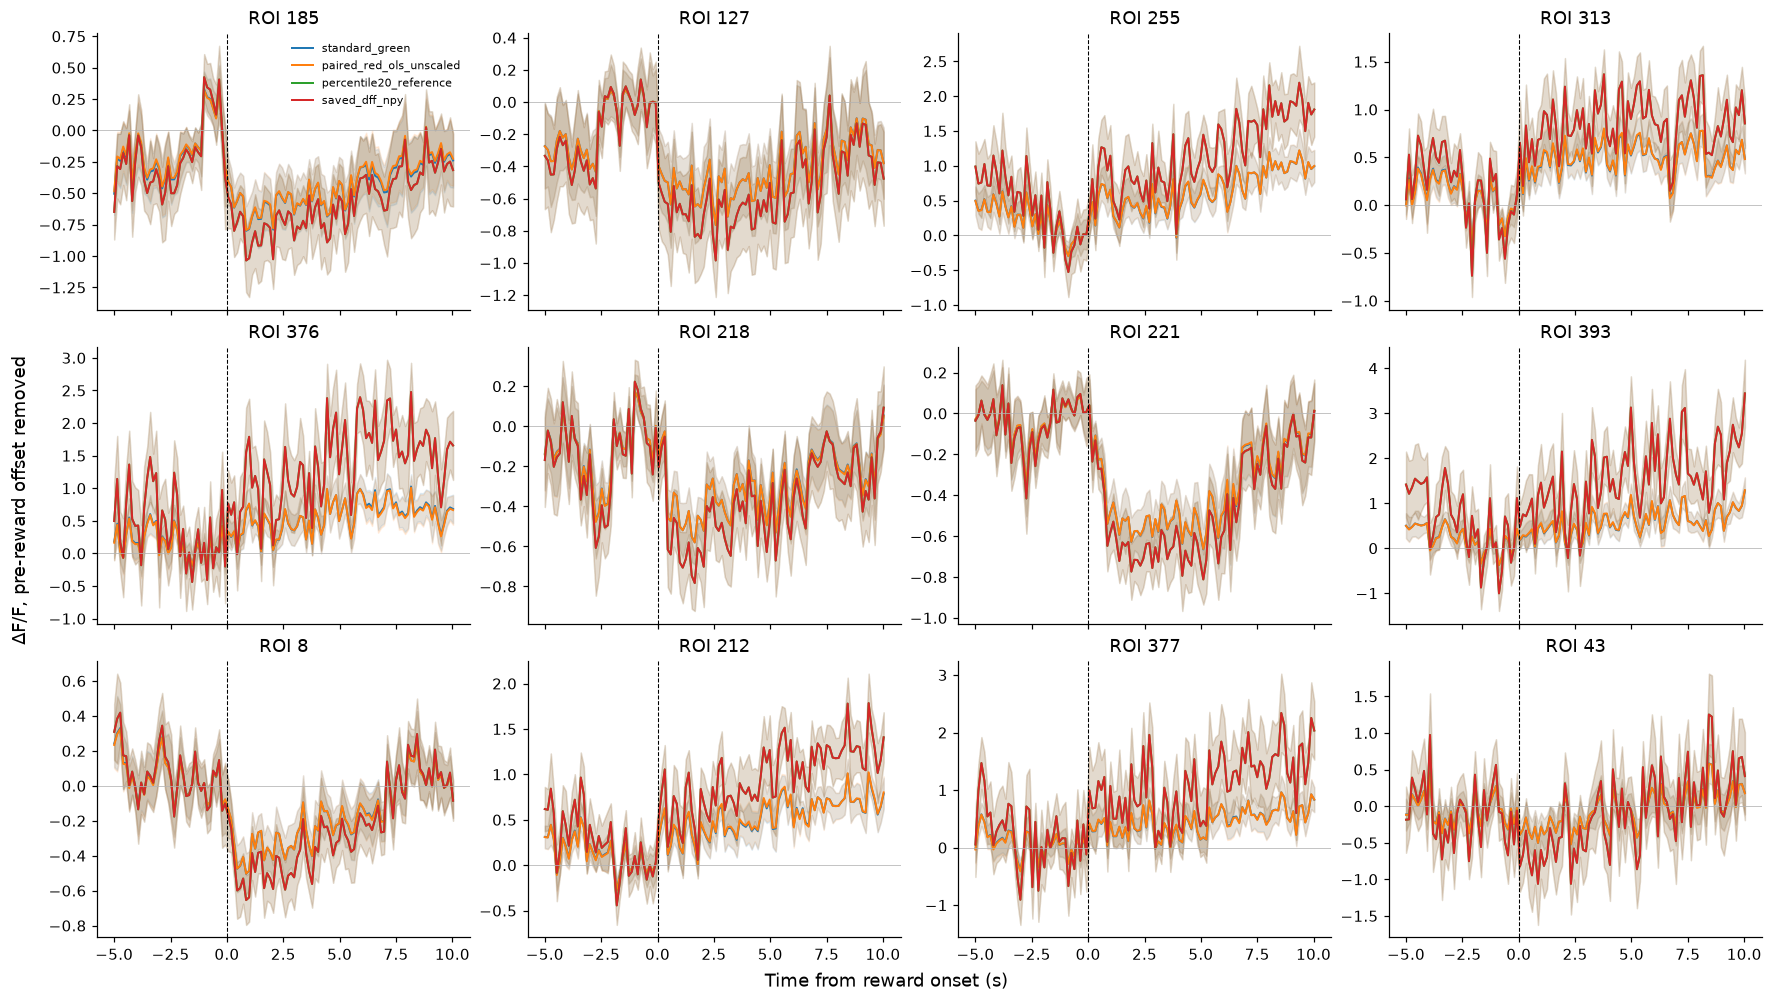

In [9]:
means, sems, scores, trial_response = {}, {}, {}, {}
for name,a in peri.items():
    means[name],sems[name],_ = mean_sem(a,axis=0)
    trial_response[name] = mean_sem(a[:,:,response_mask],axis=2)[0]
    scores[name] = mean_sem(trial_response[name],axis=0)[0]
candidate_ids = np.flatnonzero(eligible_rois & np.isfinite(scores[RANKING_METHOD]))
order = candidate_ids[np.argsort(np.abs(scores[RANKING_METHOD][candidate_ids]))[::-1]]
selected_rois = order[:N_ROIS_TO_PLOT] if ROI_IDS is None else np.asarray(ROI_IDS,dtype=int)
if not len(selected_rois) or not np.isin(selected_rois,candidate_ids).all():
    raise ValueError('Select ROIs with sufficient common reward coverage')
colors = dict(zip(methods,plt.cm.tab10(np.arange(len(methods)))))
def finish(fig,name):
    if SAVE_FIGURES: fig.savefig(OUTPUT_DIR/f'{name}.png',dpi=180,bbox_inches='tight')
    plt.show()

fig,axes = plt.subplots(int(np.ceil(len(selected_rois)/4)),4,figsize=(16,3*int(np.ceil(len(selected_rois)/4))),squeeze=False,sharex=True,constrained_layout=True)
for ax,roi in zip(axes.flat,selected_rois):
    for name in methods:
        mean,sem = means[name][roi],sems[name][roi]
        ax.plot(relative_time,mean,label=name,color=colors[name],lw=1.3)
        ax.fill_between(relative_time,mean-sem,mean+sem,color=colors[name],alpha=.12)
    ax.axvline(0,color='black',ls='--',lw=.7)
    ax.axhline(0,color='.7',lw=.5)
    ax.set_title(f'ROI {roi}')
for ax in axes.flat[len(selected_rois):]: ax.set_visible(False)
axes.flat[0].legend(fontsize=7)
fig.supxlabel('Time from reward onset (s)')
fig.supylabel('ΔF/F, pre-reward offset removed' if BASELINE_CORRECT else 'ΔF/F')
finish(fig,'same_cells_reward_method_comparison')


## Reward-magnitude tuning: one second before and after reward

Pulse-separated traces show only −1 to +1 seconds. Each trial is centered on its own mean from −1 to 0 seconds. The pulse-count tuning curve is **mean dF/F from 0 to +1 s minus mean dF/F from −1 to 0 s**, with finite-trial SEM. These tuning windows apply to all four methods and the tuning CSV, independently of the wider reward-aligned plots and their ROI ranking. The same reward events and selected cells are retained; tuning-specific coverage is checked in these two short windows. This pre/post subtraction is always applied for tuning, independently of `BASELINE_CORRECT` for the wider plots.

In [ ]:
# Re-extract from the original method arrays: use only the tuning windows,
# not the wider plot's baseline or its per-trial eligibility mask.
tuning_time = np.arange(-int(np.floor(abs(TUNING_BASELINE_S[0])/dt)),
                        int(np.floor(TUNING_RESPONSE_S[1]/dt))+1) * dt
tuning_pre = (tuning_time >= TUNING_BASELINE_S[0]) & (tuning_time < TUNING_BASELINE_S[1])
tuning_post = (tuning_time >= TUNING_RESPONSE_S[0]) & (tuning_time <= TUNING_RESPONSE_S[1])
if not tuning_pre.any() or not tuning_post.any():
    raise ValueError('Tuning windows contain no samples')
tuning_peri, tuning_trial_response = {}, {}
for name, values in methods.items():
    a = peri_event(values, frame_times, original_ids, common_valid,
                   reward_onsets, tuning_time, 1.5*dt)
    keep = ((np.mean(np.isfinite(a[:,:,tuning_pre]),axis=2) >= MIN_VALID_FRACTION)
            & (np.mean(np.isfinite(a[:,:,tuning_post]),axis=2) >= MIN_VALID_FRACTION)
            & eligible_rois[None,:])
    a -= mean_sem(a[:,:,tuning_pre],axis=2)[0][:,:,None]
    a[~keep] = np.nan
    tuning_peri[name] = a
    tuning_trial_response[name] = mean_sem(a[:,:,tuning_post],axis=2)[0]

mag_mean,mag_sem,mag_count = {}, {}, {}
for name in methods:
    summaries = [mean_sem(tuning_trial_response[name][reward_magnitudes == mag],axis=0) for mag in magnitudes]
    mag_mean[name] = np.stack([s[0] for s in summaries],axis=1)
    mag_sem[name] = np.stack([s[1] for s in summaries],axis=1)
    mag_count[name] = np.stack([s[2] for s in summaries],axis=1)
mag_colors = plt.cm.viridis(np.linspace(.1,.9,len(magnitudes)))
# Pages of four cells keep the plots legible.
for page_start in range(0,len(selected_rois),4):
    rois = selected_rois[page_start:page_start+4]
    fig,axes = plt.subplots(len(rois),len(methods),figsize=(6*len(methods),2.8*len(rois)),squeeze=False,sharex=True,sharey='row',constrained_layout=True)
    for row,roi in enumerate(rois):
        for col,(name,a) in enumerate(tuning_peri.items()):
            ax = axes[row,col]
            for color,mag in zip(mag_colors,magnitudes):
                mean,sem,count = mean_sem(a[reward_magnitudes == mag,roi],axis=0)
                ax.plot(tuning_time,mean,color=color,label=f'{mag:g} pulses')
                ax.fill_between(tuning_time,mean-sem,mean+sem,color=color,alpha=.15)
            ax.axvline(0,color='black',ls='--',lw=.7)
            ax.axhline(0,color='.7',lw=.5)
            ax.set_title(f'ROI {roi} | {name}',fontsize=10)
            ax.set_xlim(TUNING_BASELINE_S[0], TUNING_RESPONSE_S[1])
    axes[0,-1].legend(fontsize=8)
    fig.supxlabel('Time from reward onset (s)'); fig.supylabel('ΔF/F')
    finish(fig,f'magnitude_responses_page_{page_start//4+1}')

fig,axes = plt.subplots(int(np.ceil(len(selected_rois)/4)),4,figsize=(16,3*int(np.ceil(len(selected_rois)/4))),squeeze=False,constrained_layout=True)
for ax,roi in zip(axes.flat,selected_rois):
    for name in methods:
        ax.errorbar(magnitudes,mag_mean[name][roi],yerr=mag_sem[name][roi],marker='o',lw=1,color=colors[name],label=name)
    ax.set(title=f'ROI {roi}',xlabel='Reward pulses',ylabel='ΔF/F: 0–1 s minus −1–0 s')
    ax.set_xticks(magnitudes)
for ax in axes.flat[len(selected_rois):]: ax.set_visible(False)
axes.flat[0].legend(fontsize=7)
finish(fig,'reward_magnitude_tuning')


## ROI heatmaps and trial-by-trial example

All method heatmaps share ROI ordering and color limits. No per-cell normalization is applied.

In [ ]:
lo,hi = np.nanpercentile(np.concatenate([m[order].ravel() for m in means.values()]),[1,99])
limit = max(abs(lo),abs(hi),1e-6)
fig,axes = plt.subplots(1,len(methods),figsize=(6*len(methods),7),squeeze=False,constrained_layout=True)
for ax,(name,m) in zip(axes.flat,means.items()):
    im = ax.imshow(m[order],aspect='auto',cmap='RdBu_r',vmin=-limit,vmax=limit,
                   extent=[relative_time[0],relative_time[-1],len(order),0],interpolation='nearest')
    ax.axvline(0,color='black',ls='--')
    ax.set(title=name,xlabel='Time from reward (s)',ylabel='ROI, common ordering')
fig.colorbar(im,ax=axes.ravel().tolist(),label='ΔF/F')
finish(fig,'same_order_roi_heatmaps')

example_roi = int(selected_rois[0])
trial_order = np.argsort(reward_magnitudes,kind='stable')
lo,hi = np.nanpercentile(np.concatenate([a[:,example_roi].ravel() for a in peri.values()]),[1,99])
limit = max(abs(lo),abs(hi),1e-6)
fig,axes = plt.subplots(1,len(methods),figsize=(6*len(methods),5),squeeze=False,constrained_layout=True)
for ax,(name,a) in zip(axes.flat,peri.items()):
    im = ax.imshow(a[trial_order,example_roi],aspect='auto',cmap='RdBu_r',vmin=-limit,vmax=limit,
                   extent=[relative_time[0],relative_time[-1],len(trial_order),0],interpolation='nearest')
    for boundary in np.flatnonzero(np.diff(reward_magnitudes[trial_order]) != 0)+1:
        ax.axhline(boundary,color='black',lw=.5)
    ax.axvline(0,color='black',ls='--')
    ax.set(title=f'ROI {example_roi}: {name}',xlabel='Time from reward (s)',ylabel='Trial, sorted by reward pulses')
fig.colorbar(im,ax=axes.ravel().tolist(),label='ΔF/F')
finish(fig,'example_trial_heatmaps')


## Export tuning table and optional peri-reward arrays

The compact CSV includes original ROI IDs, method, reward magnitude, mean response, SEM and valid trial count. Arrays are saved only if `SAVE_ARRAYS=True`. Source settings and analysis windows are recorded in JSON. This is one recording per run of the notebook; ROI IDs are not matched across sessions.

In [ ]:
table_rows = []
for name in methods:
    for roi in candidate_ids:
        for j,mag in enumerate(magnitudes):
            table_rows.append(dict(session=SESSION,run=RUN,roi=int(roi),method=name,
                                   reward_pulses=float(mag),mean_dff=float(mag_mean[name][roi,j]),
                                   sem=float(mag_sem[name][roi,j]),n_trials=int(mag_count[name][roi,j])))
with (OUTPUT_DIR/'reward_tuning.csv').open('w') as f:
    writer = csv.DictWriter(f,fieldnames=list(table_rows[0]))
    writer.writeheader(); writer.writerows(table_rows)
metadata = dict(session=SESSION,run=RUN,source_mode=SOURCE_MODE,source_plane=str(PLANE_DIR),
                source_dff_dir=str(DFF_DIR) if SOURCE_MODE == 'saved' else None,
                h5=str(H5_PATH),behavior=str(BEHAVIOR_TSV),normalization=normalization_source,
                methods=list(methods),ranking_method=RANKING_METHOD,
                saved_dff_path=str(SAVED_DFF_PATH) if INCLUDE_SAVED_DFF else None,
                saved_dff_metadata=saved_dff_metadata,saved_vs_percentile20=saved_dff_check,
                suite2p_parameters={k:float(ops[k]) if k != 'baseline' else str(ops[k]) for k in defaults},
                artifact_settings=manifest['artifact_detection'] if SOURCE_MODE == 'saved' else
                    dict(derivative_z=3.,minimum_fraction_cells=.25,padding_frames=1,replacement='nan'),
                baseline_correct=BASELINE_CORRECT,baseline_s=BASELINE_S,response_s=RESPONSE_S,
                window_s=WINDOW_S,minimum_valid_fraction=MIN_VALID_FRACTION,
                tuning_baseline_s=TUNING_BASELINE_S,tuning_response_s=TUNING_RESPONSE_S,
                tuning_measure="post-reward mean minus pre-reward mean",
                only_iscell=ONLY_ISCELL,selected_roi_ids=selected_rois.tolist(),
                common_sample_mask=True,gap_interpolation=False,
                matched_pulses=len(rsync['matched_pycontrol_indices']))
(OUTPUT_DIR/'analysis_settings.json').write_text(json.dumps(metadata,indent=2))
if SAVE_ARRAYS:
    for name,a in peri.items():
        np.savez_compressed(OUTPUT_DIR/f'peri_reward_{name}.npz',peri_reward=a,
                            relative_time=relative_time,trial_ids=reward_trial_ids,
                            reward_magnitudes=reward_magnitudes,original_frame_ids=original_ids)
    for name,a in tuning_peri.items():
        np.savez_compressed(OUTPUT_DIR/f'tuning_peri_reward_{name}.npz',peri_reward=a,
                            relative_time=tuning_time,trial_ids=reward_trial_ids,
                            reward_magnitudes=reward_magnitudes)
print('Saved tuning table and settings:',OUTPUT_DIR)
